<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/00-start-here/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Start Here: What AI and Machine Learning Actually Are

Before any code, it helps to know what the field is, what the words mean, and where each part of this course fits. This notebook is that map.

It's not just reading. Every idea comes with a small piece of code you can run and change: a program that learns from examples instead of following rules, one that finds groups nobody labelled, one that learns by trial and error, and a tiny text generator that works on the same principle as ChatGPT, built in about twenty lines. None of it needs any background. If some of the code looks unfamiliar, that's fine; run it, read the output, and come back to it after Module 1.

**Contents**

1. AI, machine learning, deep learning, generative AI: what the words mean
2. Rules versus learning
3. What "learning" means: parameters, loss and data
4. The kinds of machine learning
5. The central problem: generalisation and overfitting
6. Neural networks and deep learning
7. How large language models work
8. What AI can't do (yet), and why it matters
9. How a real ML project runs, and where this course covers it
10. What it takes to become an ML engineer
11. Check your understanding

In [1]:
import math
import random
from collections import Counter, defaultdict

import numpy as np

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. AI, machine learning, deep learning, generative AI

These words get used loosely, so here's how they fit together.

- **Artificial intelligence (AI)** is the broad goal: computer systems that do things we'd call intelligent if a person did them, like recognising speech, playing chess, translating, planning or answering questions. The term dates from a 1956 research workshop at Dartmouth College. AI includes approaches that don't learn at all, such as hand-written rules and search algorithms.
- **Machine learning (ML)** is the part of AI where the system **learns from data** instead of being programmed with explicit rules. You show it examples, and it adjusts itself to do better on them. Almost all modern AI is machine learning.
- **Deep learning** is machine learning with **neural networks** that have many layers. It took over around 2012, when a deep network called AlexNet won the ImageNet image recognition competition by a wide margin. It powers today's speech recognition, image recognition, translation and language models.
- **Generative AI** is deep learning used to **create** new content: text, images, audio, code. **Large language models (LLMs)**, like the ones behind ChatGPT, Claude and Gemini, are generative models for text.

Each one sits inside the one before:

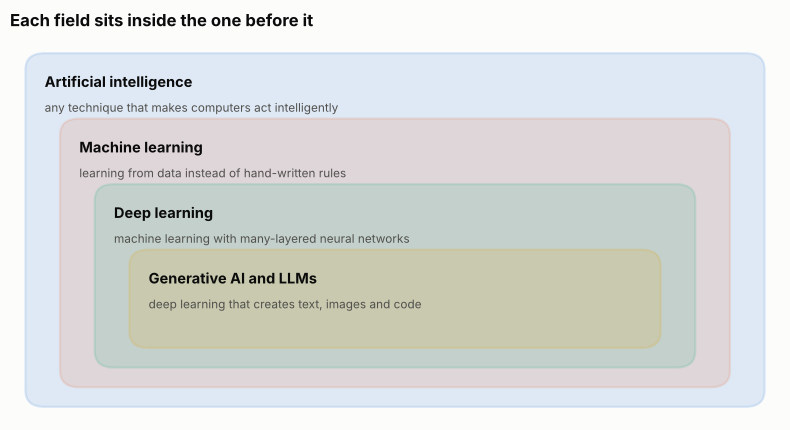

In [3]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 4.4))
layers = [
    ("Artificial intelligence", "any technique that makes computers act intelligently"),
    ("Machine learning", "learning from data instead of hand-written rules"),
    ("Deep learning", "machine learning with many-layered neural networks"),
    ("Generative AI and LLMs", "deep learning that creates text, images and code"),
]
for i, (name, note) in enumerate(layers):
    left, bottom = 0.2 + 0.45 * i, 0.2 + 0.3 * i
    width, height = 9.6 - 0.9 * i, 5.4 - 1.3 * i
    ax.add_patch(FancyBboxPatch((left, bottom), width, height, boxstyle="round,pad=0,rounding_size=0.25",
                                facecolor=PALETTE[i], alpha=0.14, edgecolor=PALETTE[i], linewidth=1.6))
    top = bottom + height
    ax.text(left + 0.25, top - 0.3, name, fontsize=10.5, fontweight="bold", color=INK, va="top")
    ax.text(left + 0.25, top - 0.72, note, fontsize=8.5, color=INK_2, va="top")
ax.set_xlim(0, 10)
ax.set_ylim(0, 5.8)
ax.axis("off")
ax.set_title("Each field sits inside the one before it")
fig.tight_layout()
plt.show()

A short history helps make sense of the present:

| years | what happened |
|---|---|
| 1950s | Alan Turing asks whether machines can think (1950); the term "artificial intelligence" is coined (1956); the **perceptron**, a single artificial neuron that learns, is built (1958) |
| 1960s to 1980s | **Rule-based** "expert systems" encode human knowledge as thousands of if-then rules. They work in narrow areas but are brittle and expensive to maintain |
| 1986 | **Backpropagation** is popularised: an efficient way to train networks with several layers (you'll build it in Modules 3 and 9) |
| 1990s to 2000s | **Statistical machine learning** takes over: decision trees, support vector machines, naive Bayes, random forests. Spam filters and recommendation systems go mainstream |
| 2012 | **Deep learning** breaks through on image recognition, helped by large labelled datasets and graphics cards (GPUs) |
| 2017 | The **Transformer** architecture is published ("Attention Is All You Need"). It becomes the basis of modern language models |
| 2018 onwards | Language models trained on huge amounts of text (BERT, the GPT series and others) get steadily more capable as they get bigger |
| 2022 | ChatGPT's release brings **generative AI** to the general public |

The pattern across all of it: methods that **learn from data** keep beating methods where people write the knowledge in by hand, as soon as there's enough data and computing power to feed them.

## 2. Rules versus learning

Here's the difference in practice. Say you want a program that decides whether a movie review is positive or negative.

The **traditional programming** approach is to write the rules yourself:

In [4]:
POSITIVE_WORDS = {"good", "great", "excellent", "loved", "wonderful", "best"}
NEGATIVE_WORDS = {"bad", "terrible", "awful", "hated", "worst", "boring"}


def rule_based(review):
    words = review.lower().replace(".", "").replace(",", "").split()
    score = sum(w in POSITIVE_WORDS for w in words) - sum(w in NEGATIVE_WORDS for w in words)
    return "positive" if score > 0 else "negative" if score < 0 else "no idea"


print(rule_based("A great film with wonderful acting."))
print(rule_based("Boring and far too long."))
print(rule_based("A masterpiece. I was moved to tears."))

positive
negative
no idea


The first two work. The third is clearly positive, but none of its words are in our lists, so the program has no idea. We could add "masterpiece" and "moved", but there will always be another word. Language has too many ways to say things for anyone to list them all.

The **machine learning** approach: instead of writing rules, collect **examples with the right answers**, and let the program work out for itself which words point which way.

In [5]:
training_reviews = [
    ("a masterpiece, moving and beautifully shot", "positive"),
    ("i loved every minute, a moving story", "positive"),
    ("brilliant acting and a beautiful score", "positive"),
    ("funny, clever and full of heart", "positive"),
    ("the best film of the year, a must see", "positive"),
    ("gripping from start to finish", "positive"),
    ("a clever script and brilliant performances", "positive"),
    ("dull, predictable and far too long", "negative"),
    ("a waste of time, i nearly walked out", "negative"),
    ("the plot made no sense and the acting was wooden", "negative"),
    ("predictable from the first scene", "negative"),
    ("too long and painfully dull", "negative"),
    ("wooden dialogue and a lazy script", "negative"),
    ("i want my money back, a total waste", "negative"),
]


def tokens(text):
    return text.lower().replace(",", " ").replace(".", " ").split()


def learn_word_weights(examples):
    """Count how often each word appears in positive and negative examples."""
    counts = {"positive": Counter(), "negative": Counter()}
    for text, label in examples:
        counts[label].update(tokens(text))
    vocabulary = sorted(set(counts["positive"]) | set(counts["negative"]))
    # a word's weight: how much more common it is in positive reviews than negative ones (log scale, smoothed)
    return {w: math.log((counts["positive"][w] + 1) / (counts["negative"][w] + 1)) for w in vocabulary}


weights = learn_word_weights(training_reviews)


def learned(review):
    score = sum(weights.get(w, 0.0) for w in tokens(review))
    return "positive" if score > 0 else "negative" if score < 0 else "no idea"


strongest = sorted(weights.items(), key=lambda kv: (kv[1], kv[0]))     # ties broken alphabetically
print("most negative words:", [w for w, _ in strongest[:5]])
print("most positive words:", [w for w, _ in strongest[-5:]])

most negative words: ['dull', 'long', 'predictable', 'too', 'waste']
most positive words: ['to', 'year', 'brilliant', 'clever', 'moving']


Nobody told the program that "dull", "predictable" or "waste" are bad signs in a review, or that "brilliant", "clever" and "moving" are good ones. It found them in the examples. Not every choice is sensible: "to" and "year" count as positive only because they happened to appear in positive reviews ("from start to finish", "the best film of the year"), and "too" and "long" look negative only because complaints about length were common. With so few examples, accidents look like patterns.

Now compare both programs on reviews **neither has seen**:

In [6]:
new_reviews = [
    ("A masterpiece. I was moved to tears.", "positive"),
    ("Clever, funny and gripping.", "positive"),
    ("Predictable and painfully long.", "negative"),
    ("Wooden acting in a lazy remake.", "negative"),
    ("A great cast wasted on a dull script.", "negative"),
]
for review, truth in new_reviews:
    print(f"{review:<40} truth: {truth:<9} rules: {rule_based(review):<9} learned: {learned(review)}")

A masterpiece. I was moved to tears.     truth: positive  rules: no idea   learned: positive
Clever, funny and gripping.              truth: positive  rules: no idea   learned: positive
Predictable and painfully long.          truth: negative  rules: no idea   learned: negative
Wooden acting in a lazy remake.          truth: negative  rules: no idea   learned: negative
A great cast wasted on a dull script.    truth: negative  rules: positive  learned: negative


The rules get none of the five right: four times they have no idea, and once they're fooled by "great" in a negative review. The learned version gets all five, including words the rules never listed. Don't read too much into a perfect score on five reviews, though. It only knows 14 examples, it reads words one at a time with no idea of order or negation ("not good" would confuse it), and it picked up accidental patterns like "to" and "year". Those problems get better with **more and better examples** and **better models**, which is what the rest of the field is about.

That's the core idea of machine learning:

> Instead of writing the rules, you write a program that **finds the rules in examples**. The quality of the result depends on the examples (the data) as much as on the program (the model).

The mini project in Module 2 builds a much better version of this, a naive Bayes spam filter, and Module 11 uses the same thinking on a real scientific dataset.

## 3. What "learning" means: parameters, loss and data

"The program learns" sounds mysterious, but what actually happens is simple. Every ML model has three ingredients:

1. **A model with adjustable numbers, called parameters.** In the review classifier, the parameters were the word weights. In a straight line `y = w·x + b`, they're `w` and `b`. A large language model has billions of them, but they're still just numbers.
2. **A loss**: a single number that measures how wrong the model's predictions are on the training examples. Lower is better.
3. **A learning algorithm** that changes the parameters to make the loss smaller. The most common one is **gradient descent**: work out which direction each parameter should move to reduce the loss, take a small step that way, and repeat.

Here it is on the smallest possible model. We have a few measurements that roughly follow a straight line, and we want the line that fits best:

In [7]:
rng = np.random.default_rng(0)
x = np.linspace(0, 10, 30)
y = 3 * x + 5 + rng.normal(0, 2, size=30)        # the "true" rule is y = 3x + 5, plus noise

w, b = 0.0, 0.0                                     # parameters: start knowing nothing
learning_rate = 0.01
history = []
for step in range(2001):
    prediction = w * x + b
    error = prediction - y
    loss = np.mean(error ** 2)                      # mean squared error
    if step in (0, 10, 100, 2000):
        history.append((step, w, b))
        print(f"step {step:>4}: loss {loss:7.2f}   w = {w:.2f}, b = {b:.2f}")
    w -= learning_rate * 2 * np.mean(error * x)     # nudge each parameter downhill
    b -= learning_rate * 2 * np.mean(error)

step    0: loss  472.10   w = 0.00, b = 0.00
step   10: loss    7.03   w = 3.59, b = 0.75
step  100: loss    4.36   w = 3.36, b = 2.28
step 2000: loss    2.62   w = 2.98, b = 4.85


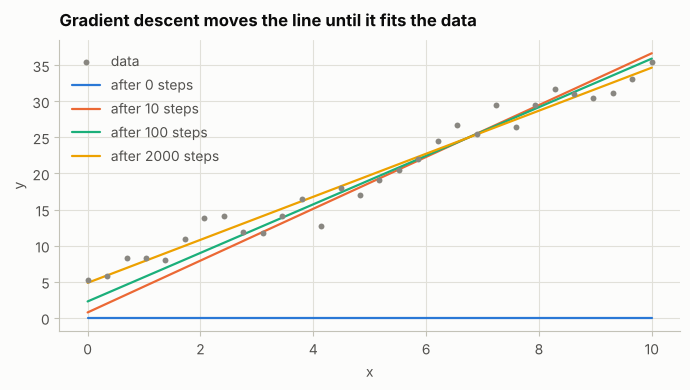

In [8]:
fig, ax = plt.subplots()
ax.scatter(x, y, color=MUTED, s=18, label="data", zorder=3)
xs = np.array([0, 10])
for (step, w_s, b_s), colour in zip(history, PALETTE):
    ax.plot(xs, w_s * xs + b_s, color=colour, label=f"after {step} steps")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Gradient descent moves the line until it fits the data")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

It starts with a flat line (`w = 0, b = 0`) and ends close to the true rule, `w = 3, b = 5`, without ever being told it. The loss went from over 400 to about 3.

That loop is, at heart, how **every** neural network is trained, including the largest language models. The model is enormously bigger and the gradients are computed automatically, but it's still: predict, measure the loss, nudge the parameters, repeat. You'll write this loop in Module 1, understand the calculus behind it in Module 9, and build the automatic gradient machinery yourself in Module 3.

## 4. The kinds of machine learning

Machine learning problems come in a few kinds, depending on what the data looks like and what feedback the model gets.

### Supervised learning: learning from labelled examples

Every training example comes with the right answer, the **label**. The review classifier above is supervised. There are two main types:

- **Classification**: the answer is a category. Spam or not, which species, which digit, positive or negative.
- **Regression**: the answer is a number. A house price, tomorrow's temperature, a penguin's body mass.

Most ML in industry is supervised. It's the focus of Part 1 of this course and of Module 12 onwards.

### Unsupervised learning: finding structure without labels

Sometimes there are no labels, and the goal is to find patterns: groups of similar customers, the main directions of variation in the data, unusual records. Here's **k-means clustering**, one of the simplest methods, finding three groups in points nobody labelled:

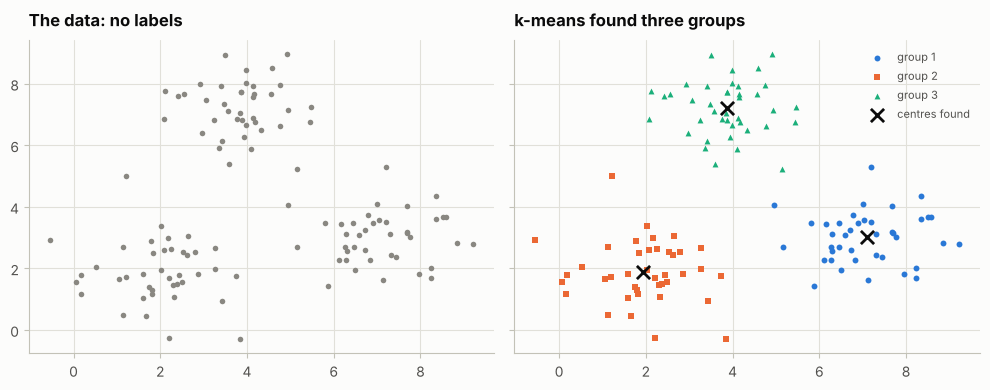

In [9]:
rng = np.random.default_rng(3)
centres_true = np.array([[2, 2], [7, 3], [4, 7]])
points = np.vstack([c + rng.normal(0, 0.9, size=(40, 2)) for c in centres_true])


def k_means(points, k, steps=10, seed=0):
    centres = points[np.random.default_rng(seed).choice(len(points), k, replace=False)]
    for _ in range(steps):
        distances = np.linalg.norm(points[:, None, :] - centres[None, :, :], axis=2)
        group = distances.argmin(axis=1)                                       # each point joins its nearest centre
        centres = np.array([points[group == j].mean(axis=0) for j in range(k)])   # each centre moves to its group's middle
    return group, centres


group, centres = k_means(points, k=3)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
axes[0].scatter(points[:, 0], points[:, 1], color=MUTED, s=16)
axes[0].set_title("The data: no labels")
for j, marker in zip(range(3), ["o", "s", "^"]):
    axes[1].scatter(points[group == j, 0], points[group == j, 1], color=PALETTE[j], marker=marker, s=18,
                    label=f"group {j + 1}")
axes[1].scatter(centres[:, 0], centres[:, 1], color=INK, marker="x", s=90, linewidths=2, label="centres found")
axes[1].set_title("k-means found three groups")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

The algorithm only repeats two steps: assign each point to its nearest centre, then move each centre to the middle of its points. Nobody told it what the groups were. Module 15 (planned) covers clustering, dimensionality reduction and anomaly detection properly.

### Reinforcement learning: learning by trial and error

An **agent** takes actions in an environment and receives **rewards**, with no labelled examples at all. It has to discover which actions pay off, balancing **exploration** (trying things to learn about them) against **exploitation** (doing what currently looks best). This is how systems learn to play games, control robots, and it's part of how chat assistants are tuned to give helpful answers.

The simplest case is a row of slot machines with unknown payout rates. The agent below mostly pulls the machine that has paid best so far, but 10% of the time it tries a random one, just in case:

In [10]:
payout_rates = [0.20, 0.50, 0.75]                   # hidden from the agent
rng = np.random.default_rng(1)

pulls = np.zeros(3)
total_reward = np.zeros(3)
for step in range(2000):
    if rng.random() < 0.1 or pulls.min() == 0:
        machine = int(rng.integers(3))               # explore
    else:
        machine = int(np.argmax(total_reward / pulls))   # exploit the best estimate so far
    reward = rng.random() < payout_rates[machine]
    pulls[machine] += 1
    total_reward[machine] += reward

for m in range(3):
    print(f"machine {m}: true rate {payout_rates[m]:.2f}, agent's estimate {total_reward[m] / pulls[m]:.2f}, "
          f"pulled {int(pulls[m])} times")

machine 0: true rate 0.20, agent's estimate 0.14, pulled 70 times
machine 1: true rate 0.50, agent's estimate 0.57, pulled 76 times
machine 2: true rate 0.75, agent's estimate 0.75, pulled 1854 times


The agent was never told which machine is best. It worked it out from rewards, and ended up spending over 90% of its pulls on the best one. Its estimate for that machine is spot on; its estimates for the others are rougher, because once it was fairly sure they were worse, it only tried them during its occasional random exploration. That's the exploration-exploitation trade-off in action: every pull spent learning about a bad machine is a pull not spent on the good one.

### Self-supervised learning: the data labels itself

The fourth kind is the one behind large language models. Take any text, hide the next word, and train the model to predict it. The "label" is just the word that actually came next, so every sentence ever written becomes training data, with no human labelling needed. Section 7 builds a tiny version.

## 5. The central problem: generalisation and overfitting

A model that's perfect on its training examples is easy to build: just memorise them. The real goal is to do well on **new** examples it hasn't seen. That's called **generalisation**, and almost every difficulty in machine learning comes back to it.

Here are 12 noisy measurements from a smooth curve. Three models of increasing flexibility try to fit them, and each is then tested on 100 **new** points from the same curve:

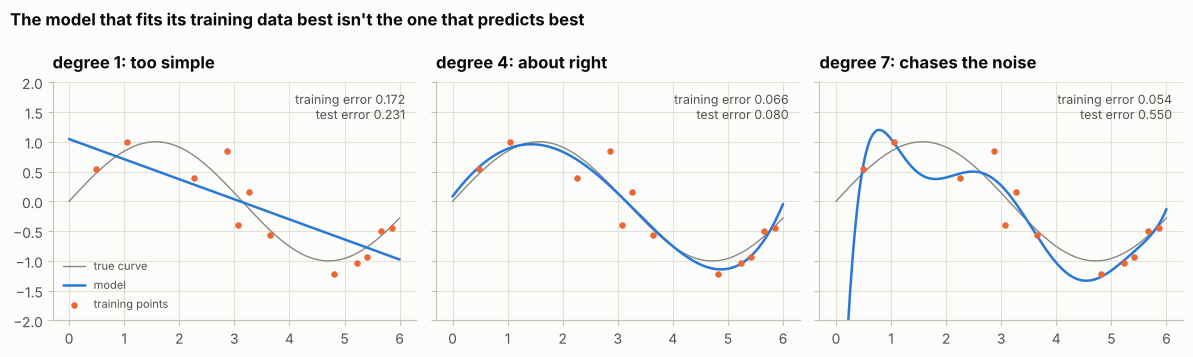

In [11]:
rng = np.random.default_rng(4)


def true_curve(x):
    return np.sin(x)


x_train = np.sort(rng.uniform(0, 6, 12))
y_train = true_curve(x_train) + rng.normal(0, 0.25, 12)
x_test = rng.uniform(0, 6, 100)
y_test = true_curve(x_test) + rng.normal(0, 0.25, 100)
grid = np.linspace(0, 6, 300)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, degree, verdict in zip(axes, [1, 4, 7], ["too simple", "about right", "chases the noise"]):
    model = np.polynomial.Polynomial.fit(x_train, y_train, degree)      # a polynomial curve of this degree
    train_error = np.mean((model(x_train) - y_train) ** 2)
    test_error = np.mean((model(x_test) - y_test) ** 2)
    ax.plot(grid, true_curve(grid), color=MUTED, linewidth=1, label="true curve")
    ax.plot(grid, model(grid), color=PALETTE[0], linewidth=1.8, label="model")
    ax.scatter(x_train, y_train, color=PALETTE[1], s=22, zorder=3, label="training points")
    ax.set_ylim(-2, 2)
    ax.set_title(f"degree {degree}: {verdict}")
    ax.text(0.97, 0.96, f"training error {train_error:.3f}\ntest error {test_error:.3f}",
            transform=ax.transAxes, fontsize=9, color=INK_2, ha="right", va="top")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("The model that fits its training data best isn't the one that predicts best",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Three outcomes, and they have names:

- **Underfitting** (left): a straight line is too simple for a curve. It's wrong on the training data and on new data.
- **A good fit** (middle): close to the training points without chasing every wiggle. Its error on new data is low.
- **Overfitting** (right): a more flexible model bends to get closer to every training point, so its training error is the lowest of the three. But it swings wildly between and beyond the points. It has fitted the **noise**, and its error on new data is several times worse than the middle model's, and worse even than the straight line's. Give it a little more flexibility and its test error explodes into the hundreds and thousands.

This is why ML practitioners never judge a model by its performance on the data it was trained on. They hold some data back as a **test set**, which the model never sees during training, and that's where the honest score comes from. Much of this course, from the train/test splits in Module 1 to the cross-validation and leakage checks in Module 11, is about getting that honest score right.

## 6. Neural networks and deep learning

A **neural network** is built from very simple units. Each **neuron** takes some numbers in, multiplies each by a weight, adds them up with a bias, and passes the result through a simple non-linear function:

In [12]:
def neuron(inputs, weights, bias):
    total = sum(i * w for i, w in zip(inputs, weights)) + bias
    return max(0.0, total)                            # "ReLU": negative totals become 0


print(neuron([0.5, 0.2, 0.9], weights=[1.2, -0.7, 0.4], bias=-0.1))

0.7200000000000001


That's all a neuron is. The power comes from combining them:

- A **layer** is many neurons reading the same inputs, each with its own weights. In code, a whole layer is one matrix multiplication (Module 6).
- A **network** stacks layers, so each layer's outputs are the next layer's inputs. Early layers learn simple patterns (edges in an image, common word pairs in text), and later layers combine them into more abstract ones (shapes, objects, meaning). "Deep" just means many layers.
- **Training** is the gradient descent loop from section 3. **Backpropagation** is the method for working out, with the chain rule, how much each of the millions of weights contributed to the loss, so each can be nudged the right way.

Why did deep learning take off in the 2010s and not earlier? The ideas were mostly known by the 1980s. What changed was **data** (the internet produced huge labelled and unlabelled datasets), **computing power** (graphics cards turned out to be very good at the matrix multiplications networks need), and a series of practical improvements in how networks are built and trained.

In this course you'll build a neuron and train a small network from scratch in Module 3, write a complete digit-recognising network in NumPy in Module 6, and (in the planned Part 3) move to PyTorch, convolutional networks for images, and Transformers for text.

## 7. How large language models work

Large language models seem like a different kind of thing, but they're built from the ideas above. At their core, they do one job:

> **Given some text, predict what comes next.**

They predict a **token** at a time. A token is a word or a piece of a word: "unbelievable" might be split into "un", "believ" and "able". A model generates a whole answer by predicting one token, adding it to the text, and predicting again.

Here's the smallest possible version: a model that predicts the next word from only the **one** word before it, by counting which words follow which in some training text. It's called a **bigram model**.

In [13]:
corpus = """
penguins live in the southern hemisphere . most penguins eat fish and krill .
gentoo penguins are larger than adelie penguins . adelie penguins live on the antarctic coast .
male penguins are often larger than female penguins . penguins cannot fly but they swim very well .
the antarctic is the coldest place on earth . krill are small animals that live in the sea .
chinstrap penguins have a thin black band under the head . scientists measure penguins every season .
scientists measure the bill and the flipper of each penguin . the sea around the antarctic is very cold .
"""
words = corpus.split()

next_word_counts = defaultdict(Counter)
for current, following in zip(words, words[1:]):
    next_word_counts[current][following] += 1

print("after 'penguins':", next_word_counts["penguins"].most_common(5))
print("after 'the':     ", next_word_counts["the"].most_common(5))

after 'penguins': [('live', 2), ('are', 2), ('.', 2), ('eat', 1), ('cannot', 1)]
after 'the':      [('antarctic', 3), ('sea', 2), ('southern', 1), ('coldest', 1), ('head', 1)]


The "model" is just a table: after "penguins", the training text continued with "are", "live" and so on, with these counts. Turning counts into probabilities and sampling from them generates new text. One extra setting, the **temperature**, controls how adventurous the sampling is:

- **Low temperature** sharpens the probabilities, so the model almost always picks the most likely word. Safe, repetitive.
- **High temperature** flattens them, so unlikely words get picked more often. Varied, but more likely to wander into nonsense.

In [14]:
def generate(start, length=14, temperature=1.0, seed=0):
    rng = np.random.default_rng(seed)
    word, output = start, [start]
    for _ in range(length):
        options = next_word_counts[word]
        if not options:
            break
        candidates = list(options)
        counts = np.array([options[w] for w in candidates], dtype=float)
        weights = counts ** (1 / temperature)                 # temperature reshapes the probabilities
        word = candidates[rng.choice(len(candidates), p=weights / weights.sum())]
        output.append(word)
    return " ".join(output)


for temperature in [0.1, 1.0, 3.0]:
    print(f"temperature {temperature}:")
    for seed in range(3):
        print("   ", generate("penguins", temperature=temperature, seed=seed))

temperature 0.1:
    penguins are larger than adelie penguins . scientists measure the antarctic is the antarctic is
    penguins are small animals that live in the antarctic is the antarctic is the antarctic
    penguins live in the antarctic is very well . the antarctic is the antarctic is
temperature 1.0:
    penguins . adelie penguins live on earth . chinstrap penguins every season . scientists measure
    penguins . scientists measure the antarctic is very well . most penguins . male penguins
    penguins eat fish and krill are small animals that live in the antarctic is very
temperature 3.0:
    penguins cannot fly but they swim very cold . the flipper of each penguin .
    penguins . scientists measure the antarctic coast . male penguins live on earth . chinstrap
    penguins eat fish and krill are small animals that live on earth . penguins cannot


Look closely at what it produces:

- At **low temperature** it gets stuck in a loop ("the antarctic is the antarctic is..."), always taking the most common next word. Real models can repeat themselves for the same reason.
- At higher temperatures, every word pair comes from the real text, but it strings them into statements that were **never** in it: "scientists measure the antarctic coast", "they swim very cold", "chinstrap penguins every season". Some are nonsense, some are plausible-sounding and false.

That second point is the root cause of a real LLM's **hallucinations**: the model is trained to produce text that's **likely**, not text that's **true**. A far bigger model makes far fewer obvious mistakes, but fluency and accuracy are still different things.

A real LLM differs from this toy in scale and architecture, not in its basic job:

| | this toy | a modern LLM |
|---|---|---|
| looks back at | 1 word | thousands to hundreds of thousands of tokens (its **context window**) |
| how | a table of counts | a **Transformer**: a deep neural network whose **attention** layers let every token draw on every earlier one |
| parameters | a few dozen counts | billions of weights |
| training text | 8 lines | trillions of tokens from books, websites, code and more |

And a raw next-token predictor isn't yet a helpful assistant. Chat models are built in stages:

1. **Pretraining**: next-token prediction on an enormous amount of text. This is where the model picks up language, facts, reasoning patterns and coding ability, and it's by far the most expensive stage.
2. **Instruction tuning**: further training on examples of instructions and good responses, so it answers questions instead of just continuing text.
3. **Preference tuning**: people (or other models) compare pairs of responses, and the model is trained towards the preferred ones. **RLHF**, reinforcement learning from human feedback, is the best-known method; it uses the reward idea from section 4.

When you use an LLM-based product, more pieces are usually involved: **retrieval** (searching documents and putting relevant passages into the context, called RAG), **tools** (letting the model run code or call other software) and safety systems. The planned Modules 19 and 20 build a small Transformer from scratch and then work with real pretrained models, embeddings and retrieval.

## 8. What AI can't do (yet), and why it matters

Understanding the limits is as important as understanding the capabilities, especially if you build these systems.

- **Models learn their training data, including its flaws.** If historical hiring data is biased, a model trained on it learns the bias. If a dataset is missing a group of people, the model will work worse for them. "The algorithm decided" is never a neutral statement.
- **Models can be confidently wrong.** A classifier always outputs a class, and an LLM always produces fluent text, even when it has no basis for an answer. Systems need ways to say "I don't know" (the capstone builds one) and people need to check important outputs.
- **The world changes.** A model trained on last year's data can quietly get worse as behaviour, equipment or language shift. This is called **drift**, and it's why deployed models need monitoring.
- **Correlation isn't causation.** A model that predicts well has found patterns, not necessarily causes. Ice cream sales predict drownings (both rise in summer); banning ice cream wouldn't help.
- **Good results on a benchmark aren't the same as good results in use.** Test sets are only as good as their resemblance to the real situation.

None of this is a reason not to use ML. It's the reason ML engineering is a skill: most of the work is making sure a model is actually right, for the right reasons, on the data it will really see.

## 9. How a real ML project runs, and where this course covers it

Real projects follow roughly the same path. Model training is one step out of many, and usually not the longest.

| step | what happens | where you learn it |
|---|---|---|
| define the problem | what exactly to predict, for whom, and how success is measured | Modules 7 (churn) and 11 (capstone brief) |
| get the data | files, databases, APIs; versions and fingerprints | Modules 5, 7, 10 |
| explore and clean | missing values, errors, units, odd IDs | Modules 5, 7, 8, 11 |
| features | turning raw data into model inputs, without leaking the future | Modules 7, 11 |
| split | training, validation and test data that match real use | Modules 1, 9, 11 |
| train | fitting models, from scratch and with libraries | Modules 1, 3, 6, 9, 11 |
| evaluate | baselines, intervals, cross-validation, error analysis | Modules 8, 9, 11 |
| package | code as a tested project; models saved with their preprocessing | Modules 5, 10, 11 |
| deploy | serving predictions through an API | Module 11 |
| monitor | logging, drift checks, retraining | Modules 10, 11 |

Python is the language for nearly all of it, which is why Part 1 of this course teaches Python and machine learning together, with every Python feature shown in an ML setting.

## 10. What it takes to become an ML engineer

An ML engineer builds systems that learn from data and keeps them working in the real world. It takes four kinds of skill, and this course is organised around them:

1. **Programming**: fluent Python, data structures, clean and tested code. *Part 1, Modules 1 to 4 and 10.*
2. **Data**: loading, cleaning, exploring and visualising real data, and spotting what's wrong with it. *Part 1, Modules 5 to 8.*
3. **Mathematics and ML fundamentals**: enough linear algebra, calculus, probability and statistics to understand what models do, and how to evaluate them honestly. *Module 9, Module 11, and Part 2 (planned).*
4. **Modern models and systems**: deep learning, computer vision, language models, and the engineering to deploy them responsibly. *Module 11 and Part 3 (planned).*

**How to get the most out of the course:**

- **Do the exercises before reading the solutions.** The checks tell you exactly which case your code gets wrong. Struggling with a bug for twenty minutes teaches more than reading the answer.
- **Change the code.** Every notebook runs in Colab. Change a learning rate, delete a line, feed in strange data, and predict what will happen before you run it.
- **Build the projects, then extend them.** Each mini project ends with ideas to take it further. Those extensions are where real understanding comes from.
- **Then build something of your own**, on data you care about. Expertise comes from projects where nobody has prepared the data or checked the answer for you.

**Good next reading**, alongside or after the course, all free online:

- *An Introduction to Statistical Learning*, by James, Witten, Hastie, Tibshirani and Taylor: the classic, readable introduction to the statistics behind ML. <https://www.statlearning.com/>
- *Dive into Deep Learning*, by Zhang, Lipton, Li and Smola: deep learning with runnable code. <https://d2l.ai/>
- *Deep Learning*, by Goodfellow, Bengio and Courville: the standard reference on the theory. <https://www.deeplearningbook.org/>
- fast.ai's *Practical Deep Learning for Coders*: a top-down, project-first course. <https://course.fast.ai/>

## 11. Check your understanding

Try to answer each question before opening its answer.

**1. What's the difference between traditional programming and machine learning?**

<details><summary>Answer</summary>

In traditional programming, a person writes the rules and the computer applies them to data. In machine learning, the person provides data with examples of the right answers, and the computer finds the rules (as model parameters) that reproduce them.

</details>

**2. You want to predict tomorrow's electricity demand in megawatts. Classification or regression?**

<details><summary>Answer</summary>

Regression: the answer is a number. If you instead predicted "high", "medium" or "low" demand, it would be classification.

</details>

**3. A model gets 99% accuracy on its training data and 70% on the test data. What's going on?**

<details><summary>Answer</summary>

Overfitting. It has learned details and noise specific to the training examples that don't hold for new data. Fixes include a simpler model, more data, regularisation, or stopping training earlier.

</details>

**4. Why should a model never be evaluated on the data it was trained on?**

<details><summary>Answer</summary>

Because a model can score well there simply by memorising, which says nothing about how it will do on new data. Only data held back from training (a test set, or cross-validation folds) gives an honest estimate.

</details>

**5. A shop has a table of customers but no labels, and wants to find groups with similar buying habits. What kind of learning is that?**

<details><summary>Answer</summary>

Unsupervised learning, specifically clustering. There's no "right answer" for each customer; the goal is to find structure.

</details>

**6. What does an LLM actually do when it writes an answer?**

<details><summary>Answer</summary>

It repeatedly predicts the next token (a word or piece of a word) given all the text so far, adds it, and predicts again. Its neural network was trained to make these predictions on enormous amounts of text, then further tuned to follow instructions and give preferred answers.

</details>

**7. Why do LLMs sometimes state false things fluently?**

<details><summary>Answer</summary>

They're trained to produce text that's likely given their training data and the context, not text that's checked to be true. A plausible-sounding combination of words can be false, as the bigram generator showed on a tiny scale. Retrieval of trusted sources, tool use and human checking reduce the problem.

</details>

**8. In the slot machine example, why does the agent sometimes pick a machine at random instead of the best one so far?**

<details><summary>Answer</summary>

Exploration. Early on its estimates are based on very few pulls and could be wrong. Occasionally trying other options lets it discover that a machine is better than it looked, instead of getting stuck with an early, lucky guess.

</details>

## Where to go next

Open **Module 1: Python Foundations** and start there, even if you've written Python before: it's written with ML in mind, and its last section fits a line with gradient descent, in plain Python, from scratch.

The [glossary](glossary.md) in this folder defines the terms used throughout the course, and is worth keeping open in another tab.